In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import preprocessing

In [4]:
import pandas as pd

df = pd.read_excel(r"C:\Users\Hooshmand\Desktop\12.xlsx")

df.head()

,کد طرح,شناسه ملی,نام شرکت,نام سکو,نوع ضمانت,درصد سود,مبلغ پروژه (میلیون ریال),تاریخ شروع,تاریخ پایان,مدت طرح (ماه),هشدار,متن مرجع
0,2390,10380113276,جهان افروز,ایساتیس کراد,بانکی,45.0,250000000000,1405/01/09,1406/01/20,12,مبلغ پیدا نشد,نام طرح: تأمین سرمایۀ در گردش جهت تولید و فروش...
1,2392,14013348736,شرکت گوهردشت,ایساتیس کراد,بانکی,45.0,250000000000,1405/01/09,1406/01/30,12,مبلغ پیدا نشد | نوع ضمانت پیدا نشد,نام طرح: تأمین سرمایۀ در گردش جهت خرید و فروش ...
2,2407,14009774167,پخش گستران متانت کبیر,زیما,بانکی,45.0,150000000000,1405/01/19,1406/02/19,12,NaN,نام طرح: تأمین سرمایه در گردش خریدوفروش عدس. د...
3,2408,14009251178,سامان میهن توان آریا,ایده فاند,بانکی,47.0,250000000000,1405/01/19,1406/02/03,12,NaN,نام طرح: تامین سرمایه در گردش واردات گوشت منجم...
4,2398,14008808189,آرمان سدید آسیا,یکتاکراد,صندوق,47.0,1500000000000,1405/01/19,1406/01/26,12,NaN,نام طرح: تأمین سرمایه در گردش جهت تولید ابزار ...


In [5]:
df.describe()

,کد طرح,درصد سود,مدت طرح (ماه)
count,739.000000,739.000000,739.000000
mean,2767.376184,45.088363,11.653586
std,228.212975,4.215859,1.499466
min,1827.000000,15.500000,3.000000
25%,2574.500000,45.000000,12.000000
50%,2766.000000,46.000000,12.000000
75%,2961.500000,47.000000,12.000000
max,3187.000000,60.000000,12.000000


In [6]:
cdf = df[['درصد سود', 'نوع ضمانت', 'مبلغ پروژه (میلیون ریال)', 'نام سکو','مدت طرح (ماه)']]
print(cdf.head(10))


   درصد سود نوع ضمانت مبلغ پروژه (میلیون ریال)       نام سکو  مدت طرح (ماه)
0      45.0     بانکی             250000000000  ایساتیس کراد             12
1      45.0     بانکی             250000000000  ایساتیس کراد             12
2      45.0     بانکی             150000000000          زیما             12
3      47.0     بانکی             250000000000     ایده فاند             12
4      47.0     صندوق            1500000000000      یکتاکراد             12
5      45.0     بانکی             250000000000      یکتاکراد             12
6      47.0     صندوق             250000000000          زیما             12
7      17.5     بانکی             250000000000      هم‌آفرین              5
8      45.0     بانکی             200000000000  ایساتیس کراد             12
9      17.5     بانکی             250000000000      هم‌آفرین              5


In [8]:
df.shape
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 739 entries, 0 to 738
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   کد طرح                    739 non-null    int64  
 1   شناسه ملی                 739 non-null    object 
 2   نام شرکت                  739 non-null    object 
 3   نام سکو                   739 non-null    object 
 4   نوع ضمانت                 739 non-null    object 
 5   درصد سود                  739 non-null    float64
 6   مبلغ پروژه (میلیون ریال)  739 non-null    object 
 7   تاریخ شروع                739 non-null    object 
 8   تاریخ پایان               739 non-null    object 
 9   مدت طرح (ماه)             739 non-null    int64  
 10  هشدار                     584 non-null    object 
 11  متن مرجع                  739 non-null    object 
dtypes: float64(1), int64(2), object(9)
memory usage: 69.4+ KB


In [9]:
df["هشدار"].value_counts(dropna=False)

هشدار
درصد سود پیدا نشد | مبلغ پیدا نشد | نوع ضمانت پیدا نشد                        192
NaN                                                                           155
نوع ضمانت پیدا نشد                                                            121
درصد سود پیدا نشد | نوع ضمانت پیدا نشد                                        112
مبلغ پیدا نشد | نوع ضمانت پیدا نشد                                             67
مبلغ پیدا نشد                                                                  57
                                                                               24
نام شرکت پیدا نشد | درصد سود پیدا نشد | مبلغ پیدا نشد | نوع ضمانت پیدا نشد      4
نام شرکت پیدا نشد | درصد سود پیدا نشد | نوع ضمانت پیدا نشد                      2
درصد سود پیدا نشد | مبلغ پیدا نشد                                               2
درصد سود پیدا نشد                                                               2
نام شرکت پیدا نشد | مبلغ پیدا نشد | نوع ضمانت پیدا نشد                          1
Name: coun

In [10]:
cdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 739 entries, 0 to 738
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   درصد سود                  739 non-null    float64
 1   نوع ضمانت                 739 non-null    object 
 2   مبلغ پروژه (میلیون ریال)  739 non-null    object 
 3   نام سکو                   739 non-null    object 
 4   مدت طرح (ماه)             739 non-null    int64  
dtypes: float64(1), int64(1), object(3)
memory usage: 29.0+ KB


In [11]:
cdf.isna().sum()

درصد سود                    0
نوع ضمانت                   0
مبلغ پروژه (میلیون ریال)    0
نام سکو                     0
مدت طرح (ماه)               0
dtype: int64

In [12]:
cdf.isna().sum()

درصد سود                    0
نوع ضمانت                   0
مبلغ پروژه (میلیون ریال)    0
نام سکو                     0
مدت طرح (ماه)               0
dtype: int64

In [13]:
cdf['مبلغ پروژه (میلیون ریال)'].head(20).tolist()

[250000000000,
 250000000000,
 150000000000,
 250000000000,
 1500000000000,
 250000000000,
 250000000000,
 250000000000,
 200000000000,
 250000000000,
 250000000000,
 250000000000,
 150000000000,
 250000000000,
 250000000000,
 250000000000,
 250000000000,
 250000000000,
 250000000000,
 200000000000]

In [14]:
cdf['مبلغ پروژه (میلیون ریال)'] = pd.to_numeric(
    cdf['مبلغ پروژه (میلیون ریال)'],
    errors='coerce'
)

C:\Users\Hooshmand\AppData\Local\Temp\ipykernel_2308\460985652.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cdf['مبلغ پروژه (میلیون ریال)'] = pd.to_numeric(


In [15]:
cdf = df[['درصد سود', 'نوع ضمانت', 'مبلغ پروژه (میلیون ریال)', 'نام سکو', 'مدت طرح (ماه)']].copy()

In [16]:
cdf['مبلغ پروژه (میلیون ریال)'] = pd.to_numeric(
    cdf['مبلغ پروژه (میلیون ریال)'],
    errors='coerce'
)

In [17]:
cdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 739 entries, 0 to 738
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   درصد سود                  739 non-null    float64
 1   نوع ضمانت                 739 non-null    object 
 2   مبلغ پروژه (میلیون ریال)  730 non-null    float64
 3   نام سکو                   739 non-null    object 
 4   مدت طرح (ماه)             739 non-null    int64  
dtypes: float64(2), int64(1), object(2)
memory usage: 29.0+ KB


In [18]:
df[["کد طرح", "درصد سود", "مبلغ پروژه (میلیون ریال)", "مدت طرح (ماه)"]].describe()

,کد طرح,درصد سود,مدت طرح (ماه)
count,739.000000,739.000000,739.000000
mean,2767.376184,45.088363,11.653586
std,228.212975,4.215859,1.499466
min,1827.000000,15.500000,3.000000
25%,2574.500000,45.000000,12.000000
50%,2766.000000,46.000000,12.000000
75%,2961.500000,47.000000,12.000000
max,3187.000000,60.000000,12.000000


In [19]:
df["مبلغ پروژه (میلیون ریال)"].isna().sum()

np.int64(0)

In [20]:
df[["تاریخ شروع", "تاریخ پایان"]].head(10)

,تاریخ شروع,تاریخ پایان
0,1405/01/09,1406/01/20
1,1405/01/09,1406/01/30
2,1405/01/19,1406/02/19
3,1405/01/19,1406/02/03
4,1405/01/19,1406/01/26
5,1405/01/19,1406/01/22
6,1405/01/18,1406/02/17
7,1405/01/17,1405/06/18
8,1405/01/17,1406/02/08
9,1405/01/16,1405/06/16


In [21]:
df[["کد طرح", "درصد سود", "مبلغ پروژه (میلیون ریال)", "مدت طرح (ماه)"]].describe()

,کد طرح,درصد سود,مدت طرح (ماه)
count,739.000000,739.000000,739.000000
mean,2767.376184,45.088363,11.653586
std,228.212975,4.215859,1.499466
min,1827.000000,15.500000,3.000000
25%,2574.500000,45.000000,12.000000
50%,2766.000000,46.000000,12.000000
75%,2961.500000,47.000000,12.000000
max,3187.000000,60.000000,12.000000


In [22]:
df[[
    "درصد سود",
    "مبلغ پروژه (میلیون ریال)",
    "مدت طرح (ماه)"
]].describe()

,درصد سود,مدت طرح (ماه)
count,739.000000,739.000000
mean,45.088363,11.653586
std,4.215859,1.499466
min,15.500000,3.000000
25%,45.000000,12.000000
50%,46.000000,12.000000
75%,47.000000,12.000000
max,60.000000,12.000000


In [23]:
df["نوع ضمانت"].value_counts()

نوع ضمانت
بانکی      558
صندوق       90
 بانکی      47
چکی         21
 صندوق      16
بانکی        4
  بانکی      3
Name: count, dtype: int64

In [24]:
mapping = {
    "ضمانت نامه بانکی": 1,
    "صندوق": 2,
    "چکی": 3
}

df["نوع ضمانت"] = df["نوع ضمانت"].map(mapping)


In [25]:
df["نوع ضمانت"].value_counts(dropna=False)

نوع ضمانت
NaN    628
2.0     90
3.0     21
Name: count, dtype: int64

In [26]:
mapping = {
    "بانکی": 1,
    "صندوق": 2,
    "چکی": 3
}

df["نوع ضمانت"] = df["نوع ضمانت"].map(mapping)

In [27]:
df["نوع ضمانت"].value_counts(dropna=False)

نوع ضمانت
NaN    739
Name: count, dtype: int64

In [28]:
df["نوع ضمانت"].value_counts(dropna=False)

نوع ضمانت
NaN    739
Name: count, dtype: int64

In [ ]:
print(df["نوع ضمانت"].dtype)
print(df["نوع ضمانت"].head())

In [ ]:
print(df.columns)

In [30]:
%whos

Variable        Type         Data/Info
--------------------------------------
cdf             DataFrame    Shape: (739, 5)
df              DataFrame    Shape: (739, 12)
mapping         dict         n=3
np              module       <module 'numpy' from 'C:\<...>ges\\numpy\\__init__.py'>
pd              module       <module 'pandas' from 'C:<...>es\\pandas\\__init__.py'>
plt             module       <module 'matplotlib.pyplo<...>\\matplotlib\\pyplot.py'>
preprocessing   module       <module 'sklearn.preproce<...>processing\\__init__.py'>
viz             DataFrame    Shape: (739, 5)


In [31]:
print(cdf["نوع ضمانت"].head())
print(viz["نوع ضمانت"].head())

0    بانکی
1    بانکی
2    بانکی
3    بانکی
4    صندوق
Name: نوع ضمانت, dtype: object
0    بانکی
1    بانکی
2    بانکی
3    بانکی
4    صندوق
Name: نوع ضمانت, dtype: object


In [32]:
df["نوع ضمانت"] = cdf["نوع ضمانت"].copy()

In [33]:
df["نوع ضمانت"] = df["نوع ضمانت"].str.strip()

In [34]:
print(df["نوع ضمانت"].value_counts())

نوع ضمانت
بانکی    612
صندوق    106
چکی       21
Name: count, dtype: int64


In [35]:
mapping = {
    "بانکی": 1,
    "صندوق": 2,
    "چکی": 3
}

df["نوع ضمانت"] = df["نوع ضمانت"].map(mapping)

In [36]:
print(df["نوع ضمانت"].value_counts(dropna=False))

نوع ضمانت
1    612
2    106
3     21
Name: count, dtype: int64


In [37]:
df["نام سکو"].value_counts()

نام سکو
زیما                 73
ایساتیس کراد         58
حلال فاند            45
هم‌آفرین             42
یکتاکراد             37
نوین کراد            34
هم‌آشنا              33
کاریزما کراد         31
کارن کراد            29
پولسار               27
اسمارت فاندینگ       23
آیفاند               22
جمع‌سپار             16
آی‌بی کراد           15
گلرنگ کراد           15
شریف کراد            13
قلک کراود            13
ترنج کراد            12
اینوستوران           12
ایده فاند            12
دانایان کراد         11
پرش                  11
کارمایه              10
مسکن پلاس            10
سپهرینو              10
رای فاند             10
کارآمد کراد          10
ملت کراد              9
مهرگان کراد           8
پتروکراد              8
وستا کراد             6
کیان کراد             5
رضوی                  5
داناک کراد            5
اوپال کراد            5
پیشران کراد           4
صباکراد               4
سپهر کراد             4
جهش کراد              4
فارابی کراد           4
پویان کراد            3
فاندوکرا

In [38]:
df["نام سکو"] = df["نام سکو"].str.strip()

In [39]:
df["نام سکو"].nunique()

60

In [40]:
df["نام سکو"].value_counts()

نام سکو
زیما                 73
ایساتیس کراد         58
حلال فاند            45
هم‌آفرین             42
یکتاکراد             37
نوین کراد            34
هم‌آشنا              33
کاریزما کراد         31
کارن کراد            29
پولسار               27
اسمارت فاندینگ       23
آیفاند               22
جمع‌سپار             16
آی‌بی کراد           15
گلرنگ کراد           15
شریف کراد            13
قلک کراود            13
ترنج کراد            12
اینوستوران           12
ایده فاند            12
دانایان کراد         11
پرش                  11
کارمایه              10
مسکن پلاس            10
سپهرینو              10
رای فاند             10
کارآمد کراد          10
ملت کراد              9
مهرگان کراد           8
پتروکراد              8
وستا کراد             6
کیان کراد             5
رضوی                  5
داناک کراد            5
اوپال کراد            5
پیشران کراد           4
صباکراد               4
سپهر کراد             4
جهش کراد              4
فارابی کراد           4
پویان کراد            3
فاندوکرا

In [41]:
print("تعداد نام‌های یکتا:", df["نام سکو"].nunique())
print("تعداد مقادیر خالی:", df["نام سکو"].isna().sum())

print(df["نام سکو"].value_counts(dropna=False).to_string())

تعداد نام‌های یکتا: 60
تعداد مقادیر خالی: 0
نام سکو
زیما                 73
ایساتیس کراد         58
حلال فاند            45
هم‌آفرین             42
یکتاکراد             37
نوین کراد            34
هم‌آشنا              33
کاریزما کراد         31
کارن کراد            29
پولسار               27
اسمارت فاندینگ       23
آیفاند               22
جمع‌سپار             16
آی‌بی کراد           15
گلرنگ کراد           15
شریف کراد            13
قلک کراود            13
ترنج کراد            12
اینوستوران           12
ایده فاند            12
دانایان کراد         11
پرش                  11
کارمایه              10
مسکن پلاس            10
سپهرینو              10
رای فاند             10
کارآمد کراد          10
ملت کراد              9
مهرگان کراد           8
پتروکراد              8
وستا کراد             6
کیان کراد             5
رضوی                  5
داناک کراد            5
اوپال کراد            5
پیشران کراد           4
صباکراد               4
سپهر کراد             4
جهش کراد              4
فارابی کراد 

In [42]:
for name in sorted(df["نام سکو"].dropna().unique()):
    print(repr(name))

'آرمان کراد'
'آیفاند'
'آی\u200cبی کراد'
'ابتکارکراد'
'استارتامین'
'اسمارت فاندینگ'
'امیدکراد'
'اوج فاند'
'اوپال کراد'
'ایده فاند'
'ایساتیس کراد'
'اینوستوران'
'ترنج کراد'
'جمع\u200cسپار'
'جهش کراد'
'حلال فاند'
'خانه سرمایه\u200cگذاری'
'داریک کراد'
'داناک کراد'
'دانایان کراد'
'رای فاند'
'رضوی'
'زچ'
'زیما'
'سپهر کراد'
'سپهرینو'
'شریف کراد'
'شهرکراد'
'صباکراد'
'فارابی کراد'
'فاندوکراد'
'فنکام فاند'
'قلک کراود'
'لقمان'
'لوتوس کراد'
'مبین کراد'
'مسکن پلاس'
'معیار کراد'
'ملت کراد'
'مهرگان کراد'
'نوین استارت'
'نوین کراد'
'هم\u200cآشنا'
'هم\u200cآفرین'
'وستا کراد'
'پاداش کراد'
'پتروکراد'
'پرش'
'پولسار'
'پویان کراد'
'پیشران کراد'
'کارآمد کراد'
'کارمایه'
'کارن کراد'
'کاریزما کراد'
'کراد خاورمیانه'
'کیان کراد'
'گرین کراد'
'گلرنگ کراد'
'یکتاکراد'


In [43]:
print(df["مبلغ پروژه (میلیون ریال)"].dtype)
print(df["مبلغ پروژه (میلیون ریال)"].isna().sum())
print(df["مبلغ پروژه (میلیون ریال)"].head(10))

object
0
0     250000000000
1     250000000000
2     150000000000
3     250000000000
4    1500000000000
5     250000000000
6     250000000000
7     250000000000
8     200000000000
9     250000000000
Name: مبلغ پروژه (میلیون ریال), dtype: object


In [44]:
df["مبلغ پروژه (میلیون ریال)"] = pd.to_numeric(
    df["مبلغ پروژه (میلیون ریال)"],
    errors="coerce"
)

In [45]:
print(df["مبلغ پروژه (میلیون ریال)"].dtype)
print(df["مبلغ پروژه (میلیون ریال)"].isna().sum())
print(df["مبلغ پروژه (میلیون ریال)"].describe())

float64
9
count    7.300000e+02
mean     9.825096e+11
std      1.849931e+13
min      1.000000e+10
25%      2.000000e+11
50%      2.500000e+11
75%      2.500000e+11
max      5.000000e+14
Name: مبلغ پروژه (میلیون ریال), dtype: float64


In [46]:
bad_values = df.loc[
    df["مبلغ پروژه (میلیون ریال)"].isna(),
    ["کد طرح", "نام شرکت", "مبلغ پروژه (میلیون ریال)"]
]

print(bad_values)

     کد طرح                                           نام شرکت  \
42     2441                                        استان تهران   
51     2438                   تعاونی صنایع چوب آفتاب آسیا شمال   
171    2576  یاران پلاستیک متحد پارسیان با اتکا به سابقه اج...   
194    2599               مهندسی جوزی و همکاران در حوزه مدیریت   
275    2673                             کوهستان سبز نگین باختر   
330    2725                               گروه طلای خلاق درریس   
341    2748                                  توسن صنعت آپادانا   
431    2845                                       خوش نوش کویر   
505    2917             کشت و صنعت و دامپروری افق قلعه پارسیان   

     مبلغ پروژه (میلیون ریال)  
42                        NaN  
51                        NaN  
171                       NaN  
194                       NaN  
275                       NaN  
330                       NaN  
341                       NaN  
431                       NaN  
505                       NaN  


In [47]:
df.nlargest(
    10, "مبلغ پروژه (میلیون ریال)"
)[["کد طرح", "نام شرکت", "مبلغ پروژه (میلیون ریال)"]]

,کد طرح,نام شرکت,مبلغ پروژه (میلیون ریال)
234,2641,تک تیم فن,5.000000e+14
402,2797,معدنی و فرآوری سرمه فیروزآباد,5.000000e+12
451,2816,معدنی و فرآوری سرمه فیروزآباد,5.000000e+12
607,3017,شامل پارافین مایع,5.000000e+12
628,3053,ریسندگی و بافندگی زرباف یزد,5.000000e+12
66,2455,بانى همراه نسل نو,2.500000e+12
118,2457,مهندسی و ساخت کسراوند اجرا,2.500000e+12
434,2841,گروه صنعتی نوین چوب و صنعت آسیا,2.500000e+12
192,2602,کاسپین کوهدشت,2.000000e+12
4,2398,آرمان سدید آسیا,1.500000e+12


In [48]:
print(cdf.columns.tolist())

['درصد سود', 'نوع ضمانت', 'مبلغ پروژه (میلیون ریال)', 'نام سکو', 'مدت طرح (ماه)']


In [49]:
print(
    df.nlargest(10, "مبلغ پروژه (میلیون ریال)")[
        ["کد طرح", "نام شرکت", "مبلغ پروژه (میلیون ریال)"]
    ].to_string(index=False)
)

 کد طرح                        نام شرکت  مبلغ پروژه (میلیون ریال)
   2641                       تک تیم فن              5.000000e+14
   2797   معدنی و فرآوری سرمه فیروزآباد              5.000000e+12
   2816   معدنی و فرآوری سرمه فیروزآباد              5.000000e+12
   3017               شامل پارافین مایع              5.000000e+12
   3053     ریسندگی و بافندگی زرباف یزد              5.000000e+12
   2455               بانى همراه نسل نو              2.500000e+12
   2457      مهندسی و ساخت کسراوند اجرا              2.500000e+12
   2841 گروه صنعتی نوین چوب و صنعت آسیا              2.500000e+12
   2602                   کاسپین کوهدشت              2.000000e+12
   2398                 آرمان سدید آسیا              1.500000e+12


In [50]:
print(cdf.loc[
    df["مبلغ پروژه (میلیون ریال)"].isna(),
    ["مبلغ پروژه (میلیون ریال)"]
].to_string(index=False))

 مبلغ پروژه (میلیون ریال)
                      NaN
                      NaN
                      NaN
                      NaN
                      NaN
                      NaN
                      NaN
                      NaN
                      NaN


In [52]:
import pandas as pd
df_original = pd.read_excel(r"C:\Users\Hooshmand\Desktop\12.xlsx")

print(df_original["مبلغ پروژه (میلیون ریال)"].dtype)
print(df_original["مبلغ پروژه (میلیون ریال)"].isna().sum())
print(df_original["مبلغ پروژه (میلیون ریال)"].head())

object
0
0     250000000000
1     250000000000
2     150000000000
3     250000000000
4    1500000000000
Name: مبلغ پروژه (میلیون ریال), dtype: object


In [53]:
print(df_original.shape)
print(df_original.columns.tolist())

(739, 12)
['کد طرح', 'شناسه ملی', 'نام شرکت', 'نام سکو', 'نوع ضمانت', 'درصد سود', 'مبلغ پروژه (میلیون ریال)', 'تاریخ شروع', 'تاریخ پایان', 'مدت طرح (ماه)', 'هشدار', 'متن مرجع']


In [54]:
amount_col = "مبلغ پروژه (میلیون ریال)"

amounts = df_original[amount_col]
numeric_amounts = pd.to_numeric(amounts, errors="coerce")

bad_rows = df_original.loc[
    numeric_amounts.isna(),
    ["کد طرح", "نام شرکت", amount_col]
]

print("تعداد مقادیر غیرعددی:", numeric_amounts.isna().sum())
print(bad_rows.to_string(index=False))

تعداد مقادیر غیرعددی: 9
 کد طرح                                                نام شرکت مبلغ پروژه (میلیون ریال)
   2441                                             استان تهران            80,000,000,00
   2438                        تعاونی صنایع چوب آفتاب آسیا شمال         250 ,000,000,000
   2576 یاران پلاستیک متحد پارسیان با اتکا به سابقه اجرایی شرکت           100,000,000,00
   2599                    مهندسی جوزی و همکاران در حوزه مدیریت           250,000,00,000
   2673                                  کوهستان سبز نگین باختر           250,000,00,000
   2725                                    گروه طلای خلاق درریس           100,000,000,00
   2748                                       توسن صنعت آپادانا           250,000,000,00
   2845                                            خوش نوش کویر           150,000,000,00
   2917                  کشت و صنعت و دامپروری افق قلعه پارسیان           250,000,000,00


In [55]:
amount_col = "مبلغ پروژه (میلیون ریال)"

df = df_original.copy()

df[amount_col] = pd.to_numeric(
    df[amount_col]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(" ", "", regex=False),
    errors="coerce"
)

print("مقادیر خالی:", df[amount_col].isna().sum())
print(df[amount_col].head())

مقادیر خالی: 0
0     250000000000
1     250000000000
2     150000000000
3     250000000000
4    1500000000000
Name: مبلغ پروژه (میلیون ریال), dtype: int64


In [56]:
print(
    df[["کد طرح", "نام شرکت", "مبلغ پروژه (میلیون ریال)"]]
    .head(10)
    .to_string(index=False)
)

 کد طرح                         نام شرکت  مبلغ پروژه (میلیون ریال)
   2390                       جهان افروز              250000000000
   2392                     شرکت گوهردشت              250000000000
   2407            پخش گستران متانت کبیر              150000000000
   2408             سامان میهن توان آریا              250000000000
   2398                  آرمان سدید آسیا             1500000000000
   2395               برآیند نگین بجنورد              250000000000
   2403                نواندیشان مدیانام              250000000000
   2393                آرتین بنادر اروند              250000000000
   2400 بازرگانی اعلا گستر مهدوی نیا یزد              200000000000
   2380                  زیست فناور هانا              250000000000


In [57]:
df = df.rename(columns={
    "مبلغ پروژه (میلیون ریال)": "مبلغ پروژه (ریال)"
})

In [58]:
print(df.isna().sum())

کد طرح                 0
شناسه ملی              0
نام شرکت               0
نام سکو                0
نوع ضمانت              0
درصد سود               0
مبلغ پروژه (ریال)      0
تاریخ شروع             0
تاریخ پایان            0
مدت طرح (ماه)          0
هشدار                155
متن مرجع               0
dtype: int64


In [59]:
print("تعداد ردیف‌های تکراری:", df.duplicated().sum())

تعداد ردیف‌های تکراری: 0


In [60]:
print("تعداد کدهای طرح تکراری:", df["کد طرح"].duplicated().sum())

تعداد کدهای طرح تکراری: 0


In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 739 entries, 0 to 738
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   کد طرح             739 non-null    int64  
 1   شناسه ملی          739 non-null    object 
 2   نام شرکت           739 non-null    object 
 3   نام سکو            739 non-null    object 
 4   نوع ضمانت          739 non-null    object 
 5   درصد سود           739 non-null    float64
 6   مبلغ پروژه (ریال)  739 non-null    int64  
 7   تاریخ شروع         739 non-null    object 
 8   تاریخ پایان        739 non-null    object 
 9   مدت طرح (ماه)      739 non-null    int64  
 10  هشدار              584 non-null    object 
 11  متن مرجع           739 non-null    object 
dtypes: float64(1), int64(3), object(8)
memory usage: 69.4+ KB


In [62]:
print(df[["تاریخ شروع", "تاریخ پایان"]].head(10).to_string(index=False))

تاریخ شروع تاریخ پایان
1405/01/09  1406/01/20
1405/01/09  1406/01/30
1405/01/19  1406/02/19
1405/01/19  1406/02/03
1405/01/19  1406/01/26
1405/01/19  1406/01/22
1405/01/18  1406/02/17
1405/01/17  1405/06/18
1405/01/17  1406/02/08
1405/01/16  1405/06/16


In [63]:
print("قالب تاریخ شروع:")
print(df["تاریخ شروع"].astype(str).str.len().value_counts())

print("\nقالب تاریخ پایان:")
print(df["تاریخ پایان"].astype(str).str.len().value_counts())

قالب تاریخ شروع:
تاریخ شروع
10    739
Name: count, dtype: int64

قالب تاریخ پایان:
تاریخ پایان
10    739
Name: count, dtype: int64


In [64]:
df[["سال شروع", "ماه شروع", "روز شروع"]] = (
    df["تاریخ شروع"]
    .str.split("/", expand=True)
    .astype(int)
)

print(df[["تاریخ شروع", "سال شروع", "ماه شروع", "روز شروع"]].head())

   تاریخ شروع  سال شروع  ماه شروع  روز شروع
0  1405/01/09      1405         1         9
1  1405/01/09      1405         1         9
2  1405/01/19      1405         1        19
3  1405/01/19      1405         1        19
4  1405/01/19      1405         1        19


In [65]:
df[["سال پایان", "ماه پایان", "روز پایان"]] = (
    df["تاریخ پایان"]
    .str.split("/", expand=True)
    .astype(int)
)

print(df[[
    "تاریخ پایان",
    "سال پایان",
    "ماه پایان",
    "روز پایان"
]].head())

  تاریخ پایان  سال پایان  ماه پایان  روز پایان
0  1406/01/20       1406          1         20
1  1406/01/30       1406          1         30
2  1406/02/19       1406          2         19
3  1406/02/03       1406          2          3
4  1406/01/26       1406          1         26


In [66]:

df.head(3)

,کد طرح,شناسه ملی,نام شرکت,نام سکو,نوع ضمانت,درصد سود,مبلغ پروژه (ریال),تاریخ شروع,تاریخ پایان,مدت طرح (ماه),هشدار,متن مرجع,سال شروع,ماه شروع,روز شروع,سال پایان,ماه پایان,روز پایان
0,2390,10380113276,جهان افروز,ایساتیس کراد,بانکی,45.0,250000000000,1405/01/09,1406/01/20,12,مبلغ پیدا نشد,نام طرح: تأمین سرمایۀ در گردش جهت تولید و فروش...,1405,1,9,1406,1,20
1,2392,14013348736,شرکت گوهردشت,ایساتیس کراد,بانکی,45.0,250000000000,1405/01/09,1406/01/30,12,مبلغ پیدا نشد | نوع ضمانت پیدا نشد,نام طرح: تأمین سرمایۀ در گردش جهت خرید و فروش ...,1405,1,9,1406,1,30
2,2407,14009774167,پخش گستران متانت کبیر,زیما,بانکی,45.0,150000000000,1405/01/19,1406/02/19,12,NaN,نام طرح: تأمین سرمایه در گردش خریدوفروش عدس. د...,1405,1,19,1406,2,19


In [67]:
for col in df.columns:
    print(f"{col}: {df[col].dtype}")

کد طرح: int64
شناسه ملی: object
نام شرکت: object
نام سکو: object
نوع ضمانت: object
درصد سود: float64
مبلغ پروژه (ریال): int64
تاریخ شروع: object
تاریخ پایان: object
مدت طرح (ماه): int64
هشدار: object
متن مرجع: object
سال شروع: int64
ماه شروع: int64
روز شروع: int64
سال پایان: int64
ماه پایان: int64
روز پایان: int64


In [68]:
platform_counts = df["نام سکو"].value_counts()

print(platform_counts.to_string())

نام سکو
زیما                 73
ایساتیس کراد         58
حلال فاند            45
هم‌آفرین             42
یکتاکراد             37
نوین کراد            34
هم‌آشنا              33
کاریزما کراد         31
کارن کراد            29
پولسار               27
اسمارت فاندینگ       23
آیفاند               22
جمع‌سپار             16
آی‌بی کراد           15
گلرنگ کراد           15
شریف کراد            13
قلک کراود            13
ترنج کراد            12
اینوستوران           12
ایده فاند            12
دانایان کراد         11
پرش                  11
کارمایه              10
مسکن پلاس            10
سپهرینو              10
رای فاند             10
کارآمد کراد          10
ملت کراد              9
مهرگان کراد           8
پتروکراد              8
وستا کراد             6
کیان کراد             5
رضوی                  5
داناک کراد            5
اوپال کراد            5
پیشران کراد           4
صباکراد               4
سپهر کراد             4
جهش کراد              4
فارابی کراد           4
پویان کراد            3
فاندوکرا

In [69]:
monthly_platforms = (
    df.groupby(["سال شروع", "ماه شروع", "نام سکو"])
      .size()
      .reset_index(name="تعداد پروژه")
)

print(monthly_platforms.head(20).to_string(index=False))

 سال شروع  ماه شروع        نام سکو  تعداد پروژه
     1405         1      ایده فاند            2
     1405         1   ایساتیس کراد            8
     1405         1     اینوستوران            1
     1405         1      حلال فاند            2
     1405         1           زیما            5
     1405         1      قلک کراود            1
     1405         1      نوین کراد            2
     1405         1       هم‌آفرین            3
     1405         1         پولسار            3
     1405         1      کارن کراد            1
     1405         1     گلرنگ کراد            1
     1405         1       یکتاکراد            2
     1405         2     آرمان کراد            1
     1405         2         آیفاند            2
     1405         2     آی‌بی کراد            3
     1405         2     استارتامین            2
     1405         2 اسمارت فاندینگ            3
     1405         2      ایده فاند            3
     1405         2   ایساتیس کراد           11
     1405         2     اینوستوران      

In [70]:
print("تاریخ شروع اولین پروژه:", df["تاریخ شروع"].min())
print("تاریخ شروع آخرین پروژه:", df["تاریخ شروع"].max())

print("\nتعداد ماه‌های مختلف:")
print(df[["سال شروع", "ماه شروع"]].drop_duplicates().shape[0])

print("\nتعداد پروژه در هر ماه:")
print(
    df.groupby(["سال شروع", "ماه شروع"])
      .size()
      .sort_index()
      .to_string()
)

تاریخ شروع اولین پروژه: 1405/01/09
تاریخ شروع آخرین پروژه: 1405/06/31

تعداد ماه‌های مختلف:
6

تعداد پروژه در هر ماه:
سال شروع  ماه شروع
1405      1            31
          2           117
          3           125
          4           118
          5           152
          6           196


In [71]:
platform_summary = (
    df.groupby("نام سکو")
      .agg(
          تعداد_پروژه=("کد طرح", "count"),
          میانگین_مبلغ=("مبلغ پروژه (ریال)", "mean"),
          میانه_مبلغ=("مبلغ پروژه (ریال)", "median"),
          میانگین_سود=("درصد سود", "mean"),
          میانگین_مدت=("مدت طرح (ماه)", "mean")
      )
      .sort_values("تعداد_پروژه", ascending=False)
)

print(platform_summary.head(15).round(2).to_string())

                تعداد_پروژه  میانگین_مبلغ    میانه_مبلغ  میانگین_سود  میانگین_مدت
نام سکو                                                                          
زیما                     73  2.489726e+11  2.500000e+11        46.50        12.00
ایساتیس کراد             58  2.343103e+11  2.500000e+11        45.34        12.00
حلال فاند                45  2.845556e+11  2.500000e+11        44.69        11.51
هم‌آفرین                 42  2.558333e+11  2.500000e+11        43.23        11.52
یکتاکراد                 37  1.375622e+13  2.500000e+11        46.76        12.00
نوین کراد                34  4.211765e+11  2.500000e+11        45.59        12.00
هم‌آشنا                  33  2.369697e+11  2.500000e+11        46.86        11.64
کاریزما کراد             31  5.293548e+11  2.500000e+11        43.94        12.00
کارن کراد                29  2.644828e+11  2.500000e+11        41.07        10.07
پولسار                   27  3.020370e+11  2.500000e+11        41.48        12.00
اسمارت فاندینگ  

In [72]:
print(
    df.nlargest(10, "مبلغ پروژه (ریال)")[
        ["کد طرح", "نام شرکت", "نام سکو", "مبلغ پروژه (ریال)"]
    ].to_string(index=False)
)

 کد طرح                        نام شرکت      نام سکو  مبلغ پروژه (ریال)
   2641                       تک تیم فن     یکتاکراد    500000000000000
   2797   معدنی و فرآوری سرمه فیروزآباد  کارآمد کراد      5000000000000
   2816   معدنی و فرآوری سرمه فیروزآباد  کارآمد کراد      5000000000000
   3017               شامل پارافین مایع کاریزما کراد      5000000000000
   3053     ریسندگی و بافندگی زرباف یزد    نوین کراد      5000000000000
   2455               بانى همراه نسل نو کاریزما کراد      2500000000000
   2457      مهندسی و ساخت کسراوند اجرا     پتروکراد      2500000000000
   2841 گروه صنعتی نوین چوب و صنعت آسیا   پویان کراد      2500000000000
   2602                   کاسپین کوهدشت    حلال فاند      2000000000000
   2398                 آرمان سدید آسیا     یکتاکراد      1500000000000


In [73]:
df.sort_values(
    "مبلغ پروژه (ریال)",
    ascending=False
)[["کد طرح", "نام شرکت", "نام سکو", "مبلغ پروژه (ریال)"]].head(20)


,کد طرح,نام شرکت,نام سکو,مبلغ پروژه (ریال)
234,2641,تک تیم فن,یکتاکراد,500000000000000
607,3017,شامل پارافین مایع,کاریزما کراد,5000000000000
628,3053,ریسندگی و بافندگی زرباف یزد,نوین کراد,5000000000000
402,2797,معدنی و فرآوری سرمه فیروزآباد,کارآمد کراد,5000000000000
451,2816,معدنی و فرآوری سرمه فیروزآباد,کارآمد کراد,5000000000000
66,2455,بانى همراه نسل نو,کاریزما کراد,2500000000000
434,2841,گروه صنعتی نوین چوب و صنعت آسیا,پویان کراد,2500000000000
118,2457,مهندسی و ساخت کسراوند اجرا,پتروکراد,2500000000000
192,2602,کاسپین کوهدشت,حلال فاند,2000000000000
4,2398,آرمان سدید آسیا,یکتاکراد,1500000000000


In [74]:
mask = df["مبلغ پروژه (ریال)"] > 500_000_000_000

print("تعداد ردیف‌های مشمول اصلاح:", mask.sum())

df.loc[mask, "مبلغ پروژه (ریال)"] = (
    df.loc[mask, "مبلغ پروژه (ریال)"] // 1000
)

print("مبالغ اصلاح‌شده:")
print(
    df.loc[mask, ["کد طرح", "نام شرکت", "نام سکو", "مبلغ پروژه (ریال)"]]
    .to_string(index=False)
)

تعداد ردیف‌های مشمول اصلاح: 16
مبالغ اصلاح‌شده:
 کد طرح                        نام شرکت      نام سکو  مبلغ پروژه (ریال)
   2398                 آرمان سدید آسیا     یکتاکراد         1500000000
   2455               بانى همراه نسل نو کاریزما کراد         2500000000
   2457      مهندسی و ساخت کسراوند اجرا     پتروکراد         2500000000
   2602                   کاسپین کوهدشت    حلال فاند         2000000000
   2606                   تمدن وزین قرن    کارن کراد          750000000
   2641                       تک تیم فن     یکتاکراد       500000000000
   2797   معدنی و فرآوری سرمه فیروزآباد  کارآمد کراد         5000000000
   2800                 الوند دانه خمین    نوین کراد         1000000000
   2841 گروه صنعتی نوین چوب و صنعت آسیا   پویان کراد         2500000000
   2816   معدنی و فرآوری سرمه فیروزآباد  کارآمد کراد         5000000000
   2888                     رایسا انرژی    قلک کراود         1000000000
   2945                سردینه سازان توس         رضوی         1000000000
   3017         

In [75]:
df["مبلغ پروژه (ریال)"].describe().apply(lambda x: f"{x:,.0f}")



count                739
mean     246,023,477,673
std      128,154,612,727
min          600,000,000
25%      150,000,000,000
50%      250,000,000,000
75%      250,000,000,000
max      500,000,000,000
Name: مبلغ پروژه (ریال), dtype: object

In [76]:
platform_summary = (
    df.groupby("نام سکو")
    .agg(
        تعداد_پروژه=("کد طرح", "count"),
        میانگین_مبلغ=("مبلغ پروژه (ریال)", "mean"),
        میانه_مبلغ=("مبلغ پروژه (ریال)", "median"),
        میانگین_سود=("درصد سود", "mean"),
        میانگین_مدت=("مدت طرح (ماه)", "mean")
    )
    .sort_values("تعداد_پروژه", ascending=False)
)

platform_summary.head(15).round(2)

,تعداد_پروژه,میانگین_مبلغ,میانه_مبلغ,میانگین_سود,میانگین_مدت
نام سکو,,,,,
زیما,73,2.489726e+11,2.500000e+11,46.50,12.00
ایساتیس کراد,58,2.343103e+11,2.500000e+11,45.34,12.00
حلال فاند,45,2.401556e+11,2.500000e+11,44.69,11.51
هم‌آفرین,42,2.558333e+11,2.500000e+11,43.23,11.52
یکتاکراد,37,2.157162e+11,2.500000e+11,46.76,12.00
نوین کراد,34,2.448824e+11,2.500000e+11,45.59,12.00
هم‌آشنا,33,2.369697e+11,2.500000e+11,46.86,11.64
کاریزما کراد,31,2.876613e+11,2.500000e+11,43.94,12.00
کارن کراد,29,2.386466e+11,2.500000e+11,41.07,10.07


In [79]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

X = df[
    ["نوع ضمانت", "درصد سود", "مبلغ پروژه (ریال)",
     "مدت طرح (ماه)", "سال شروع", "ماه شروع"]
]
y = df["نام سکو"].astype(str).str.strip()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42

)

preprocessor = ColumnTransformer(
    transformers=[
        ("guarantee", OneHotEncoder(handle_unknown="ignore"), ["نوع ضمانت"])
    ],
    remainder="passthrough"
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("\nگزارش ارزیابی:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.216

گزارش ارزیابی:
                precision    recall  f1-score   support

    آرمان کراد       0.00      0.00      0.00         0
        آیفاند       0.67      0.50      0.57         4
    آی‌بی کراد       0.40      1.00      0.57         2
    ابتکارکراد       0.00      0.00      0.00         1
    استارتامین       0.00      0.00      0.00         1
اسمارت فاندینگ       0.00      0.00      0.00         2
      اوج فاند       0.00      0.00      0.00         0
    اوپال کراد       0.00      0.00      0.00         1
     ایده فاند       0.25      0.33      0.29         3
  ایساتیس کراد       0.33      0.18      0.24        11
    اینوستوران       0.00      0.00      0.00         1
     ترنج کراد       0.00      0.00      0.00         2
      جمع‌سپار       0.00      0.00      0.00         3
      جهش کراد       0.00      0.00      0.00         2
     حلال فاند       0.17      0.07      0.10        15
    داریک کراد       0.00      0.00      0.00         1
    داناک کراد 

In [84]:
df_model["نوع ضمانت"] = (
    df_model["نوع ضمانت"]
    .astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

print(df_model["نوع ضمانت"].value_counts())

نوع ضمانت
بانکی    417
صندوق     73
چکی       10
Name: count, dtype: int64


In [88]:
print(df_model.columns.tolist())

['کد طرح', 'شناسه ملی', 'نام شرکت', 'نام سکو', 'نوع ضمانت', 'درصد سود', 'مبلغ پروژه (ریال)', 'تاریخ شروع', 'تاریخ پایان', 'مدت طرح (ماه)', 'هشدار', 'متن مرجع', 'سال شروع', 'ماه شروع', 'روز شروع', 'سال پایان', 'ماه پایان', 'روز پایان']


In [94]:
from sklearn.cluster import AffinityPropagation
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

# تبدیل ماتریس به آرایه متراکم در صورت نیاز
X_ap = X_scaled.toarray() if hasattr(X_scaled, "toarray") else X_scaled

ap = AffinityPropagation(
    damping=0.8,
    max_iter=500,
    convergence_iter=20,
    random_state=42
)

labels_ap = ap.fit_predict(X_ap)

n_clusters = len(set(labels_ap)) - (1 if -1 in labels_ap else 0)

print("تعداد خوشه‌ها:", n_clusters)
print("تعداد نمونه‌های نماینده:", len(ap.cluster_centers_indices_))
print("تعداد تکرارها:", ap.n_iter_)

if 1 < n_clusters < len(labels_ap):
    print(
        "Silhouette Score:",
        round(silhouette_score(X_ap, labels_ap), 3)
    )
else:
    print("برای محاسبه Silhouette به بیش از یک خوشه و کمتر از تعداد کل نمونه‌ها نیاز داریم.")

تعداد خوشه‌ها: 32
تعداد نمونه‌های نماینده: 32
تعداد تکرارها: 169
Silhouette Score: 0.465


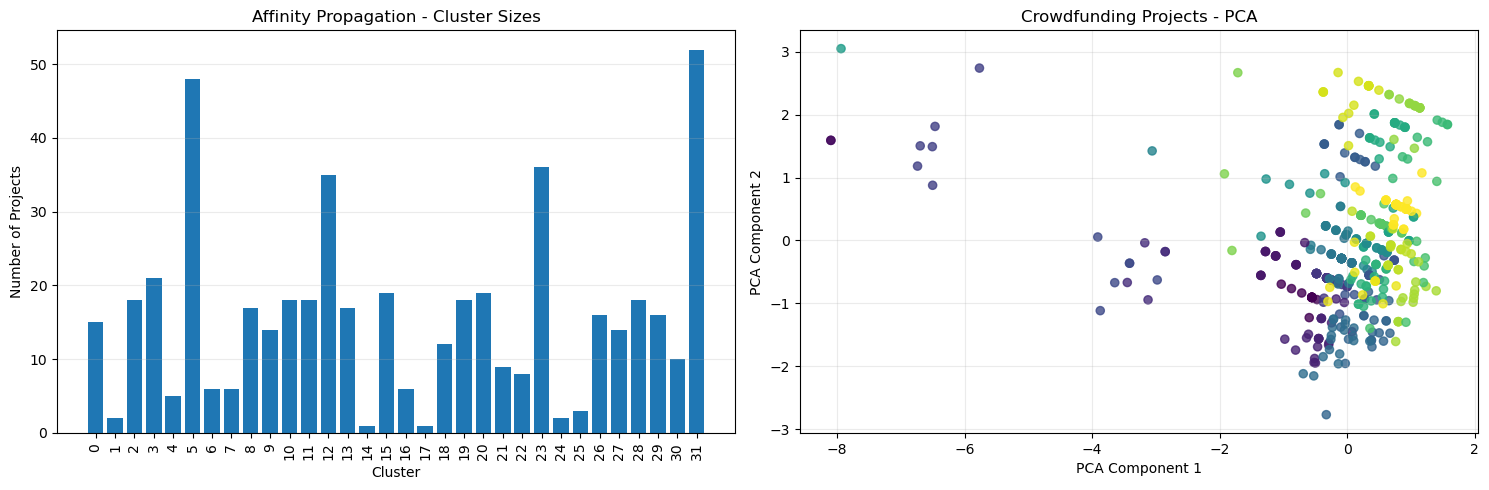

تعداد پروژه‌های هر خوشه:


,تعداد پروژه
خوشه,
0,15
1,2
2,18
3,21
4,5
5,48
6,6
7,6
8,17


In [95]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

df_ap = df_model.loc[X.index].copy()
df_ap["خوشه"] = labels_ap

# تعداد پروژه‌ها در هر خوشه
cluster_sizes = df_ap["خوشه"].value_counts().sort_index()

# آماده‌سازی داده برای نمودار دوبعدی
X_dense = X_scaled.toarray() if hasattr(X_scaled, "toarray") else X_scaled
X_pca = PCA(n_components=2, random_state=42).fit_transform(X_dense)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# نمودار اندازه خوشه‌ها
axes[0].bar(cluster_sizes.index.astype(str), cluster_sizes.values)
axes[0].set_title("Affinity Propagation - Cluster Sizes")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Number of Projects")
axes[0].tick_params(axis="x", rotation=90)
axes[0].grid(axis="y", alpha=0.25)

# نمایش پروژه‌ها در فضای دوبعدی PCA
axes[1].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels_ap, s=35, alpha=0.8
)
axes[1].set_title("Crowdfunding Projects - PCA")
axes[1].set_xlabel("PCA Component 1")
axes[1].set_ylabel("PCA Component 2")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("تعداد پروژه‌های هر خوشه:")
display(cluster_sizes.rename("تعداد پروژه").to_frame())

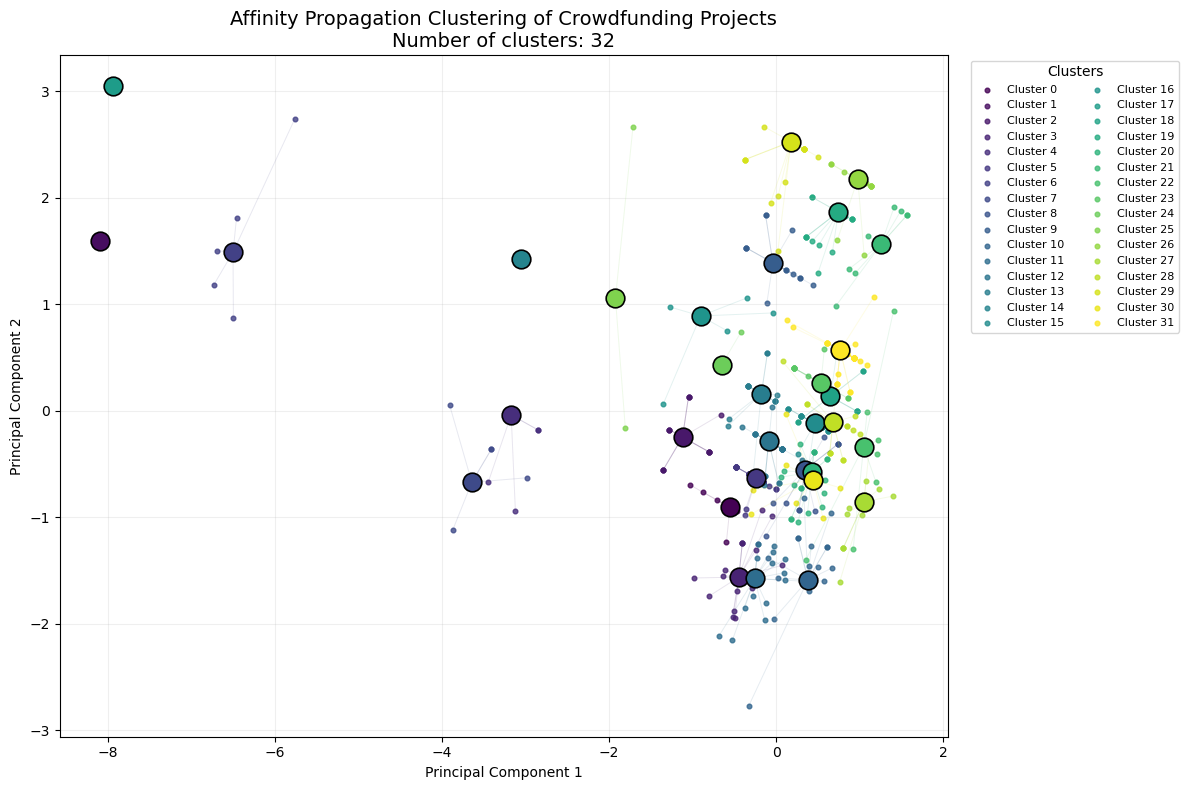

تعداد خوشه‌ها: 32
درصد واریانس توضیح‌داده‌شده توسط دو مؤلفه: 62.31 %


In [96]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# تبدیل ویژگی‌ها به دو بعد برای ترسیم
X_dense = X_scaled.toarray() if hasattr(X_scaled, "toarray") else X_scaled
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_dense)

# برچسب خوشه‌ها و مراکز واقعی الگوریتم
labels = labels_ap
center_indices = ap.cluster_centers_indices_
n_clusters = len(center_indices)

# رسم نمودار
plt.close("all")
fig, ax = plt.subplots(figsize=(12, 8))

colors = plt.cm.viridis(np.linspace(0, 1, n_clusters))

for k, color in zip(range(n_clusters), colors):
    members = labels == k
    center = X_2d[center_indices[k]]

    # نقاط متعلق به خوشه
    ax.scatter(
        X_2d[members, 0],
        X_2d[members, 1],
        color=color,
        marker=".",
        s=45,
        alpha=0.8,
        label=f"Cluster {k}"
    )

    # مرکز خوشه
    ax.scatter(
        center[0],
        center[1],
        s=180,
        color=color,
        marker="o",
        edgecolor="black",
        linewidth=1.2,
        zorder=5
    )

    # اتصال اعضای خوشه به مرکز
    for point in X_2d[members]:
        ax.plot(
            [center[0], point[0]],
            [center[1], point[1]],
            color=color,
            alpha=0.12,
            linewidth=0.7
        )

ax.set_title(
    f"Affinity Propagation Clustering of Crowdfunding Projects\n"
    f"Number of clusters: {n_clusters}",
    fontsize=14
)
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.grid(alpha=0.2)

# راهنمای نمودار؛ برای 32 خوشه در چند ستون
ax.legend(
    title="Clusters",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    ncol=2,
    fontsize=8
)

plt.tight_layout()
plt.show()

print("تعداد خوشه‌ها:", n_clusters)
print(
    "درصد واریانس توضیح‌داده‌شده توسط دو مؤلفه:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)